In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import ot
from sklearn.datasets import make_moons
from sklearn.datasets import make_blobs


def generate_dataset_moons_blobs(n_pos, n_unl_neg, n_unl_pos=None, dim='2d',
                                 center_blobs=None, std_blobs=None,
                                 rotated=False):
    """Generate a toy dataset. The positives are drawn according to a two-
    moons shape and the negatives according to a blob.

    Parameters
    ----------
    n_pos: number of positive examples of the P dataset

    n_unl_neg: number of negative examples of the U dataset

    n_unl_pos: number of positive examples of the U dataset (default:None)
        If None, correspond to a copy of the P dataset

    dim: string (default: '2d')
        Choose between a '2d' or '3d' P dataset

    center_blobs: array
        Coordinates of the center of the blobs

    std_blobs: array
        Std of the blobs

    rotated: boolean (default:False)
        Indicates if the positives of the U dataset should be rotated
    """

    # create the Positive dataset
    seed = 76543210
    n = 0.1
    if dim == '3d':
        n = 0.05
    P, _ = make_moons(n_samples=n_pos, noise=n, shuffle=True,
                      random_state=seed)
    P = pd.DataFrame(P, columns=['feature1', 'feature2'])
    if dim == '3d':
        P['feature3'] = np.random.normal(loc=1.0, scale=0.07, size=P.shape[0])

    # create the unlabeled dataset but negative dataset
    if center_blobs is None:
        center_blobs = [[-0.5, -0.75]]
    if std_blobs is None:
        std_blobs = 0.1
    # X_n, _ = make_blobs(n_samples=n_unl_neg, centers=center_blobs,
    #                     cluster_std=std_blobs, random_state=seed)
    # X_n = pd.DataFrame(X_n, columns=['feature1', 'feature2'])

    if n_unl_pos is not None:
        # create the unlabeled but positive dataset
        X_u_p, _ = make_moons(n_samples=n_unl_pos, noise=0.05, shuffle=True,
                              random_state=seed)
        X_u_p = pd.DataFrame(X_u_p, columns=['feature1', 'feature2'])
    else:
        X_u_p = P.copy()
        n_unl_pos = n_pos

    # Unlabeled dataset
    # U = pd.concat([X_u_p, X_n])
    U = X_u_p
    if rotated:
        angle = math.radians(-90)
        temp = U.feature1, U.feature2
        temp = (temp[0] * math.cos(angle) - temp[1] * math.sin(angle),
                temp[0] * math.sin(angle) + temp[1] * math.cos(angle))
        U.feature1 = temp[0] - 0.5
        U.feature2 = temp[1] + 0.5

    y_unl = pd.Series(np.concatenate((np.ones(n_unl_pos),
                                      np.zeros(n_unl_neg))))

    return P, U, y_unl

def generate_dataset_moons_blobs2(n_pos, n_unl_neg, n_unl_pos=None, dim='2d',
                                 center_blobs=None, std_blobs=None,
                                 rotated=False):
    """Generate a toy dataset. The positives are drawn according to a two-
    moons shape and the negatives according to a blob.

    Parameters
    ----------
    n_pos: number of positive examples of the P dataset

    n_unl_neg: number of negative examples of the U dataset

    n_unl_pos: number of positive examples of the U dataset (default:None)
        If None, correspond to a copy of the P dataset

    dim: string (default: '2d')
        Choose between a '2d' or '3d' P dataset

    center_blobs: array
        Coordinates of the center of the blobs

    std_blobs: array
        Std of the blobs

    rotated: boolean (default:False)
        Indicates if the positives of the U dataset should be rotated
    """

    # create the Positive dataset
    seed = 76543210
    n = 0.1
    if dim == '3d':
        n = 0.05
    P, _ = make_moons(n_samples=n_pos, noise=n, shuffle=True,
                      random_state=seed)
    P = pd.DataFrame(P, columns=['feature1', 'feature2'])
    if dim == '3d':
        P['feature3'] = np.random.normal(loc=1.0, scale=0.07, size=P.shape[0])

    # create the unlabeled dataset but negative dataset
    if center_blobs is None:
        center_blobs = [[-0.5, -0.75]]
    if std_blobs is None:
        std_blobs = 0.1
    X_n, _ = make_blobs(n_samples=n_unl_neg, centers=center_blobs,
                        cluster_std=std_blobs, random_state=seed)
    X_n = pd.DataFrame(X_n, columns=['feature1', 'feature2'])

    if n_unl_pos is not None:
        # create the unlabeled but positive dataset
        X_u_p, _ = make_moons(n_samples=n_unl_pos, noise=0.05, shuffle=True,
                              random_state=seed)
        X_u_p = pd.DataFrame(X_u_p, columns=['feature1', 'feature2'])
    else:
        X_u_p = P.copy()
        n_unl_pos = n_pos

    # Unlabeled dataset
    U = pd.concat([X_u_p, X_n])
    # U = X_u_p
    if rotated:
        angle = math.radians(-90)
        temp = U.feature1, U.feature2
        temp = (temp[0] * math.cos(angle) - temp[1] * math.sin(angle),
                temp[0] * math.sin(angle) + temp[1] * math.cos(angle))
        U.feature1 = temp[0] - 0.5
        U.feature2 = temp[1] + 0.5

    y_unl = pd.Series(np.concatenate((np.ones(n_unl_pos),
                                      np.zeros(n_unl_neg))))

    return P, U, y_unl

def plot_dataset(P, U, y, dim='2d', ax=None, y_hat=None, transp=None):
    """Plot a dataset

    Parameters
    ----------
    P: pandas dataframe, shape=(n_p, d_p)
        Positive dataset

    U: pandas dataframe, shape=(n_u, d_u)
        Unlabeled dataset

    y: array, len=n_u
        Labels on the unlabeled dataframe. Should be 0 (negatives) or 1 (pos)

    dim: string (default: '2d')
        Choose between a '2d' or '3d' plot

    y_hat: array, len=n_u (default: None)
        Predicted labels of the unlabeled dataframe.
        If None, no labels are displayed.
    """
    if ax is None:
        fig = plt.figure()
        if dim == '3d':
            ax = fig.add_subplot(111, projection='3d')
        else:
            ax = fig.add_subplot(111)
    if dim == '3d':
        ax.scatter(P.feature1, P.feature2, P.feature3, c='k', marker='o',
                   linewidth=1, label='P')
    elif dim == '2d':
        ax.scatter(
            P.feature1, P.feature2, c='k', marker='o', linewidth=1, s=50,
            label='P')
    else:
        raise ValueError("dim argument takes either '2d' or '3d' argument")
    if y_hat is None:
        pos_1 = np.where(y == 1)
        pos_0 = np.where(y == 0)
        if dim == '3d':
            ax.view_init(elev=40., azim=100)
            ax.scatter(U.feature1, U.feature2, zs=0, zdir='z', label='U')
        else:
            ax.scatter(
                U.iloc[pos_1].feature1, U.iloc[pos_1].feature2,
                s=70, facecolors='none', edgecolors='b', label='P+U')
            # ax.scatter(
            #     U.iloc[pos_0].feature1, U.iloc[pos_0].feature2,
            #     c='b', marker='+', linewidth=1, s=70, alpha=0.5, label='N+U')
    else:
        if dim == '3d':
            ax.view_init(elev=40., azim=100)
            ax.scatter(U.feature1, U.feature2,
                       zs=0, zdir='z', label='U', c='b')
        else:
            for i, y_i in enumerate(y):
                if (y_i == 1 and y_hat[i] == 1):
                    ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                               facecolors='none', edgecolors='b', label='P+U')
                if (y_i == 0 and y_hat[i] == 0):
                    ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                               c='b', marker='+', linewidth=1, alpha=0.5,
                               label='N+U')
                # if (y_i == 0 and y_hat[i] == 1):
                #     ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                #                facecolors='none', edgecolors='r')
                # if (y_i == 1 and y_hat[i] == 0):
                #     ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, c='r',
                #                marker='+', linewidth=1, s=70, alpha=0.5)

    ax.tick_params(axis='x', which='both', bottom=False, top=False,
                   labelbottom=False)
    ax.tick_params(axis='y', which='both', left=False, right=False,
                   labelleft=False)
    if dim == '3d':
        ax.tick_params(axis='z', which='both', left=False, right=False,
                       labelleft=False)
    if transp is not None:
        for i in range(transp.shape[0]):
            for j in range(transp.shape[1]):
                if transp[i, j] > 1e-5:
                    if dim == '2d':
                        ax.plot([P.iloc[i].feature1, U.iloc[j].feature1],
                                [P.iloc[i].feature2, U.iloc[j].feature2], 'k',
                                alpha=0.15)
                    elif dim == '3d':
                        ax.plot([P.iloc[i].feature1, U.iloc[j].feature1],
                                [P.iloc[i].feature2, U.iloc[j].feature2],
                                [P.iloc[i].feature3, 0], 'k', alpha=0.05)


def plot_datasetv2(P, U, y, dim='2d', ax=None, y_hat=None, transp=None):
    """Plot a dataset

    Parameters
    ----------
    P: pandas dataframe, shape=(n_p, d_p)
        Positive dataset

    U: pandas dataframe, shape=(n_u, d_u)
        Unlabeled dataset

    y: array, len=n_u
        Labels on the unlabeled dataframe. Should be 0 (negatives) or 1 (pos)

    dim: string (default: '2d')
        Choose between a '2d' or '3d' plot

    y_hat: array, len=n_u (default: None)
        Predicted labels of the unlabeled dataframe.
        If None, no labels are displayed.
    """
    if ax is None:
        fig = plt.figure()
        if dim == '3d':
            ax = fig.add_subplot(111, projection='3d')
        else:
            ax = fig.add_subplot(111)
    if dim == '3d':
        ax.scatter(P.feature1, P.feature2, P.feature3, c='k', marker='o',
                   linewidth=1, label='P')
    elif dim == '2d':
        ax.scatter(
            P.feature1, P.feature2, c='k', marker='o', linewidth=1, s=50,
            label='P')
    else:
        raise ValueError("dim argument takes either '2d' or '3d' argument")
    if y_hat is None:
        pos_1 = np.where(y == 1)
        pos_0 = np.where(y == 0)
        if dim == '3d':
            ax.view_init(elev=40., azim=100)
            ax.scatter(U.feature1, U.feature2, zs=0, zdir='z', label='U')
        else:
            ax.scatter(
                U.iloc[pos_1].feature1, U.iloc[pos_1].feature2,
                s=70, facecolors='none', edgecolors='b', label='P+U')
            # ax.scatter(
            #     U.iloc[pos_0].feature1, U.iloc[pos_0].feature2,
            #     c='b', marker='+', linewidth=1, s=70, alpha=0.5, label='N+U')
    else:
        if dim == '3d':
            ax.view_init(elev=40., azim=100)
            ax.scatter(U.feature1, U.feature2,
                       zs=0, zdir='z', label='U', c='b')
        else:
            for i, y_i in enumerate(y):
                if (y_i == 1 and y_hat[i] == 1):
                    if i < 35:
                        ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                                   facecolors='none', edgecolors='b', label='P+U')
                    else:
                        ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                                   facecolors='none', edgecolors='k', label='P+U')
                if (y_i == 0 and y_hat[i] == 0):
                    ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                               c='b', marker='+', linewidth=1, alpha=0.5,
                               label='N+U')
                # if (y_i == 0 and y_hat[i] == 1):
                #     ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, s=70,
                #                facecolors='none', edgecolors='r')
                # if (y_i == 1 and y_hat[i] == 0):
                #     ax.scatter(U.iloc[i].feature1, U.iloc[i].feature2, c='r',
                #                marker='+', linewidth=1, s=70, alpha=0.5)

    ax.tick_params(axis='x', which='both', bottom=False, top=False,
                   labelbottom=False)
    ax.tick_params(axis='y', which='both', left=False, right=False,
                   labelleft=False)
    if dim == '3d':
        ax.tick_params(axis='z', which='both', left=False, right=False,
                       labelleft=False)
    if transp is not None:
        for i in range(transp.shape[0]):
            for j in range(transp.shape[1]):
                if transp[i, j] > 1e-5:
                    if dim == '2d':
                        ax.plot([P.iloc[i].feature1, U.iloc[j].feature1],
                                [P.iloc[i].feature2, U.iloc[j].feature2], 'k',
                                alpha=0.15)
                    elif dim == '3d':
                        ax.plot([P.iloc[i].feature1, U.iloc[j].feature1],
                                [P.iloc[i].feature2, U.iloc[j].feature2],
                                [P.iloc[i].feature3, 0], 'k', alpha=0.05)


def annotate_transp_matrix(ax):
    ax.text(0.3, -0.05, 'Unl. positives', horizontalalignment='center',
            verticalalignment='center', transform=ax.transAxes, c='b', size=20)
    ax.text(0.85, -0.05, 'Unl. negatives', horizontalalignment='center',
            verticalalignment='center', transform=ax.transAxes, c='b', size=20)
    ax.text(-0.05, 0.51, 'Positives', horizontalalignment='center',
            verticalalignment='center', transform=ax.transAxes, rotation=90,
            size=20)
    ax.text(-0.05, 0.06, 'D', horizontalalignment='center',
            verticalalignment='center', transform=ax.transAxes, rotation=90,
            size=20)
    ax.axvline(x=5.5, color='k', linewidth=2)
    ax.axhline(y=9.5, color='k')
    ax.tick_params(axis='x', which='both', bottom=False, top=False,
                   labelbottom=False)
    ax.tick_params(axis='y', which='both', left=False, right=False,
                   labelleft=False)


def plot_matrix(ax, G):

    font_size = 20
    mx = G.max()
    ax.imshow(-G/mx, cmap='gray')
    plt.xticks([])
    plt.yticks([])
    ax.set_ylabel("Transport plan", fontsize=font_size)

In [10]:
# draw the dataset
n_pos = 70  # number of positive examples
n_unl_pos = 70  # nb of positive but unlabeled examples
n_unl_neg = 70  # nb of negative examples
n_unl = n_unl_pos+n_unl_neg
prior = n_unl_pos/n_unl
P, U, y = generate_dataset_moons_blobs(
    n_pos, n_unl_neg, n_unl_pos=n_unl_pos, dim='2d', rotated=True)

# # compute weights and cost matrices
# nb_dummies = 1
# Ctot, C1, C2, mu, nu = pgw.compute_cost_matrices(P,U,prior, 1)

In [12]:
def cal_wass(rep_0, rep_1, ot_type, alpha=0, gamma=0, div='kl'):

    rep_0, rep_1 = rep_0.values, rep_1.values
    dist = ot.dist(rep_0, rep_1)
    dist_0 = ot.dist(rep_0, rep_0)
    dist_1 = ot.dist(rep_1, rep_1)
    a = np.ones(len(rep_0)) / len(rep_0)
    b = np.ones(len(rep_1)) / len(rep_1)
    if ot_type == 'emd':
        pi = ot.emd(a, b, dist)
    if ot_type == 'fgw':
        pi = ot.gromov.fused_gromov_wasserstein(
            dist, dist_0, dist_1, a, b, alpha=alpha)
    if ot_type == 'uot':
        pi = ot.unbalanced.sinkhorn_unbalanced(
            a, b, dist, reg=0.11, reg_m=gamma)
    if ot_type == 'fugw':
        eps = 1e-4
        from fugw.mappings import FUGW
        print((rep_0.T / np.linalg.norm(rep_0.T, axis=-1,
              keepdims=True)).shape, dist_0.T.shape, dist_1.T.shape)
        mapping = FUGW(alpha=alpha, rho=gamma, eps=eps, divergence=div)

        # %%
        # Now, we fit a transport plan between source and target distributions
        # using a sinkhorn solver
        _ = mapping.fit(
            rep_0.T / np.linalg.norm(rep_0.T, axis=-1, keepdims=True),
            rep_1.T / np.linalg.norm(rep_1.T, axis=-1, keepdims=True),
            source_geometry=dist_0,
            target_geometry=dist_1,
            solver="sinkhorn",
            verbose=True
        )
        return mapping.pi
    return pi

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.32410626 0.07335017 0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


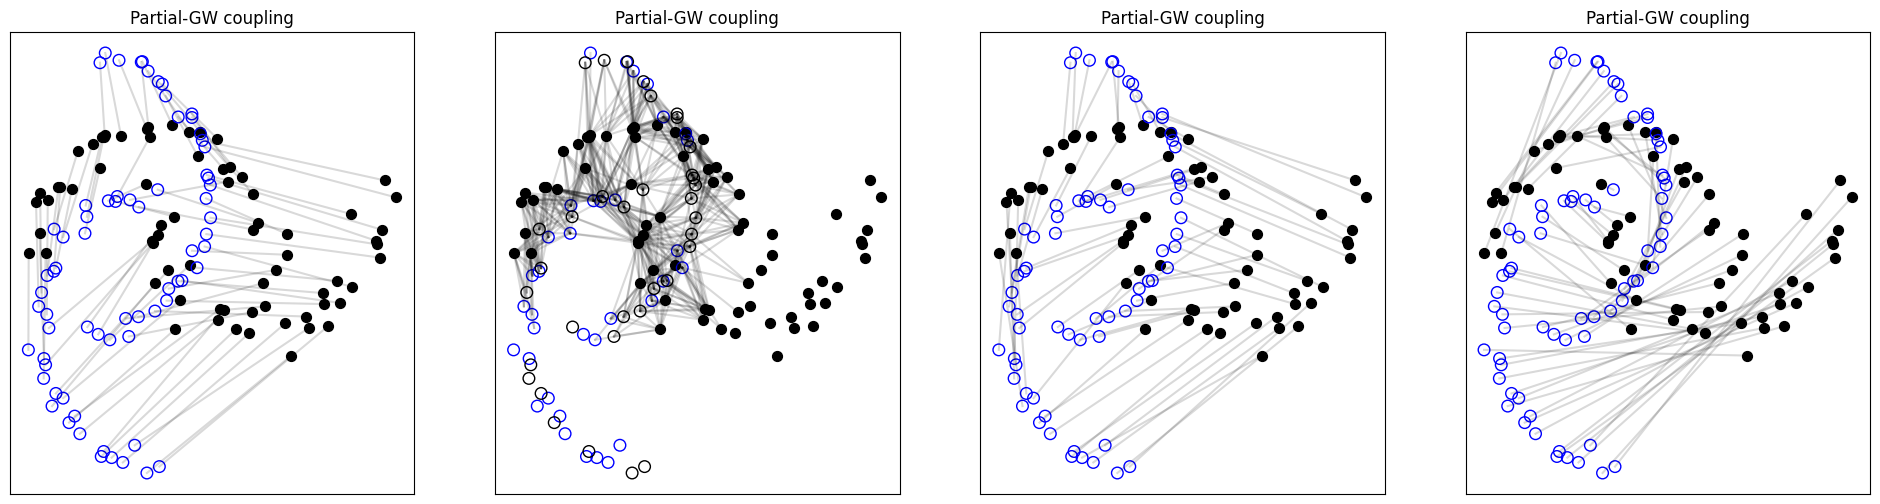

In [13]:
fig = plt.figure(figsize=(24, 6))

ax = fig.add_subplot(141)
pi = cal_wass(P, U, 'emd')
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(142)
pi = cal_wass(P, U, 'uot', alpha=1)
pi[pi < pi.mean()] = 0
y_hat = np.ones(len(y))
plot_datasetv2(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')
print(pi)

ax = fig.add_subplot(143)
pi = cal_wass(P, U, 'fgw', alpha=0.2)
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(144)
pi = cal_wass(P, U, 'fgw', alpha=1)
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.32410626 0.07335017 0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


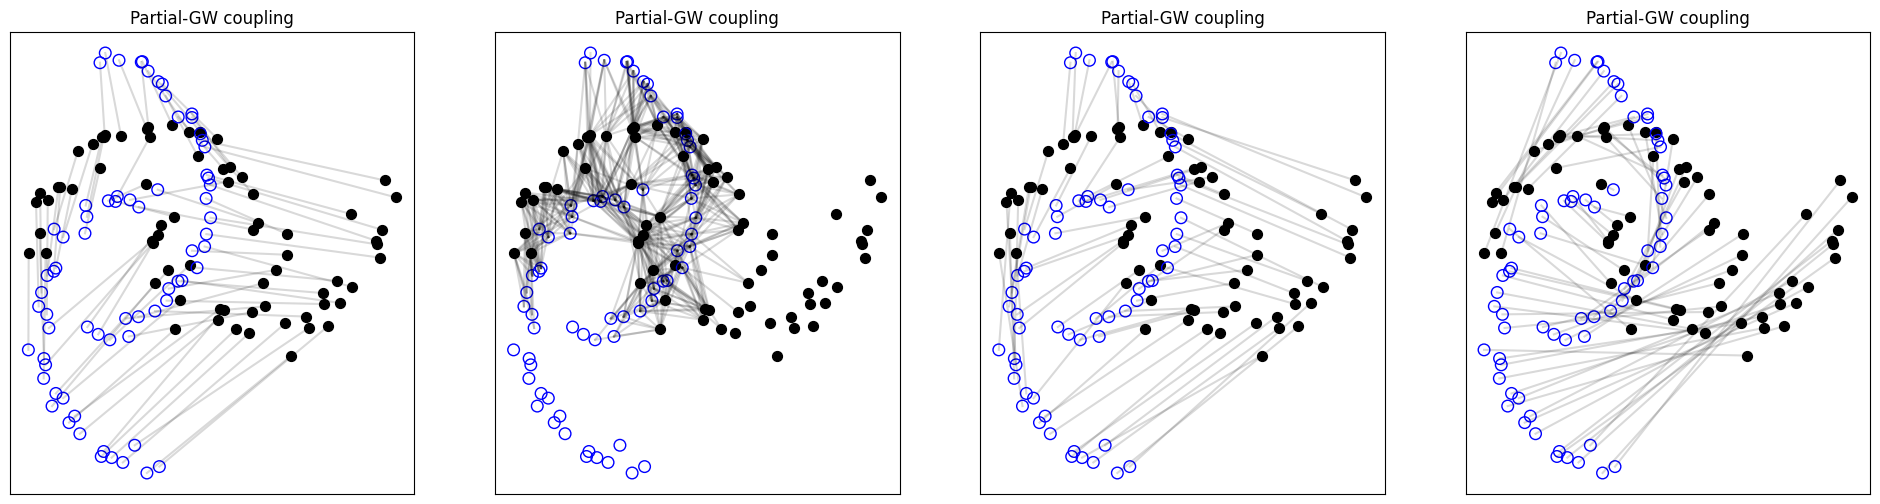

In [14]:
fig = plt.figure(figsize=(24, 6))

ax = fig.add_subplot(141)
pi = cal_wass(P, U, 'emd')
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(142)
pi = cal_wass(P, U, 'uot', alpha=1)
pi[pi < pi.mean()] = 0
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')
print(pi)

ax = fig.add_subplot(143)
pi = cal_wass(P, U, 'fgw', alpha=0.2)
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(144)
pi = cal_wass(P, U, 'fgw', alpha=1)
y_hat = np.ones(len(y))
plot_dataset(P, U, y, y_hat=y_hat, transp=pi, ax=ax)
ax.title.set_text('Partial-GW coupling')

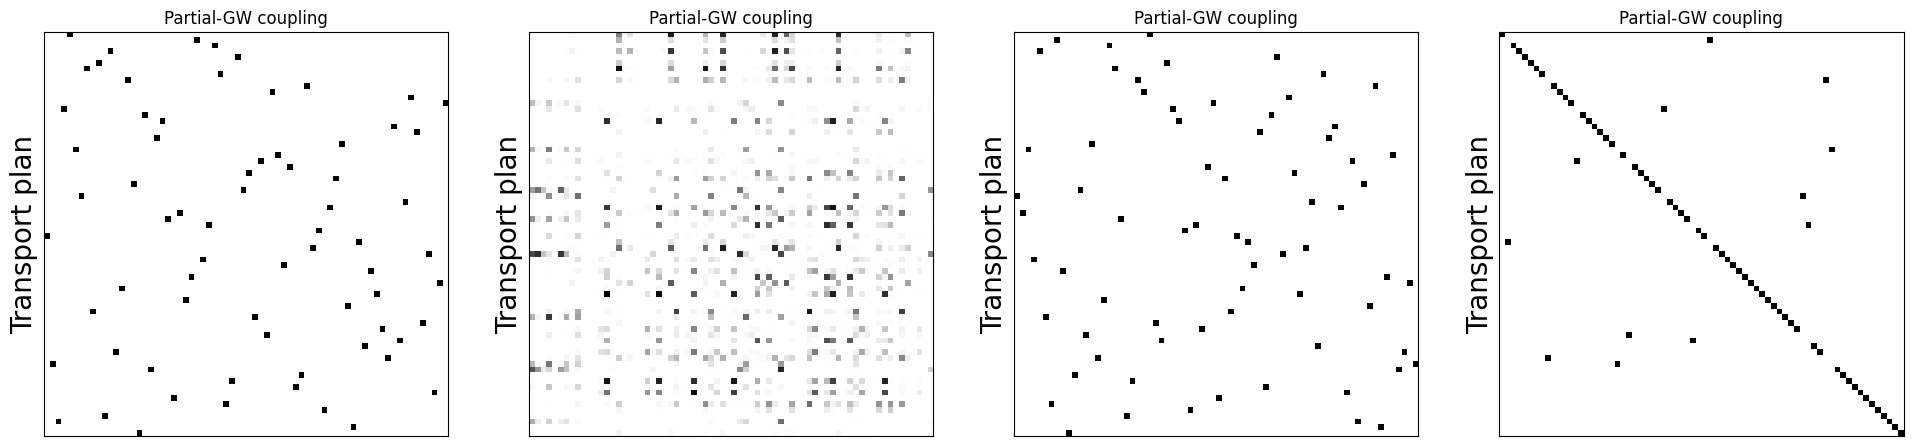

In [15]:
fig = plt.figure(figsize=(24, 6))

ax = fig.add_subplot(141)
pi = cal_wass(P, U, 'emd')
plot_matrix(ax, pi)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(142)
pi = cal_wass(P, U, 'uot', alpha=1)
plot_matrix(ax, pi)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(143)
pi = cal_wass(P, U, 'fgw', alpha=0.2)
plot_matrix(ax, pi)
ax.title.set_text('Partial-GW coupling')

ax = fig.add_subplot(144)
pi = cal_wass(P, U, 'fgw', alpha=1)
plot_matrix(ax, pi)
ax.title.set_text('Partial-GW coupling')